# ML6 – K-Means Clustering (Elbow Method)
Group sales records into clusters and choose the number of clusters (K) using the elbow method.

### Step 1: Load data and pick numeric features
`ORDERNUMBER` is just an ID, so we don't use it.

In [14]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.read_csv("sales_data_sample.csv", encoding="unicode_escape")   # file has special characters
features = ["QUANTITYORDERED", "PRICEEACH", "SALES"]

print(df.head())
print(df[features].isnull().sum())
X = StandardScaler().fit_transform(df[features])    # scale: K-Means uses distances

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

### Step 2: Elbow method
Run K-Means for K = 1 to 10 and record **inertia** (sum of squared distances of points to their cluster centre).

C:\Users\RIDDHI\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
C:\Users\RIDDHI\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
C:\Users\RIDDHI\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
C:\Users\RIDDHI\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on

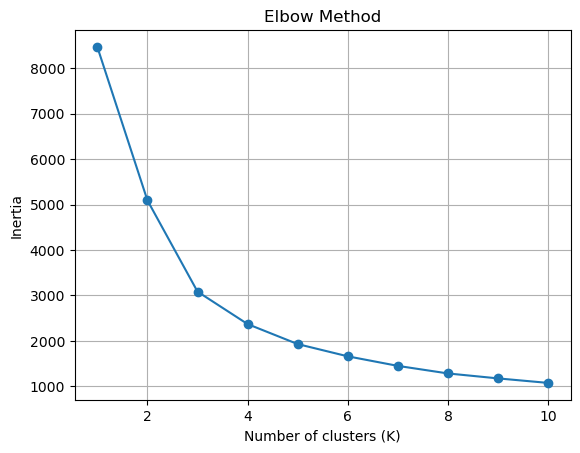

In [16]:
inertia = []
for k in range(1, 11):
    inertia.append(KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of clusters (K)"); plt.ylabel("Inertia"); plt.title("Elbow Method")
plt.grid(True); plt.show()

### Step 3: Fit K-Means with the chosen K
Look at the plot: pick the K where the curve bends like an elbow, then change `k` below if needed.

In [18]:
k = 4    # <-- set from the elbow in the plot above
df["Cluster"] = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
print(df["Cluster"].value_counts())

C:\Users\RIDDHI\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(


Cluster
2    989
1    751
3    564
0    519
Name: count, dtype: int64


### Step 4: Visualise and understand the clusters

In [ ]:
sns.scatterplot(x="PRICEEACH", y="SALES", hue="Cluster", data=df, palette="viridis")
plt.title("K-Means Clusters"); plt.show()

df.groupby("Cluster")[features].mean().round(2)     # average of each cluster